### How to load the dataset

In [2]:
!uv pip install datasets huggingface_hub pillow matplotlib
# OR
# %pip install datasets huggingface_hub pillow matplotlib

Using Python 3.12.15 environment at: /workspaces/CanopyMap/.venv
Resolved 39 packages in 1.17s                                        
Prepared 21 packages in 7.97s                                                pyarrow              ------------------------------ 51.17 MiB/51.43 MiB         pyarrow              ------------------------------ 4.27 MiB/51.43 MiB          pyarrow              ------------------------------ 1.78 MiB/51.43 MiB          pyarrow              ------------------------------ 782.78 KiB/51.43 MiB        pyarrow              ------------------------------ 653.53 KiB/51.43 MiB        pyarrow              ------------------------------ 398.78 KiB/51.43 MiB        pyarrow              ------------------------------ 270.78 KiB/51.43 MiB        pyarrow              ------------------------------ 254.78 KiB/51.43 MiB        pyarrow              ------------------------------ 238.78 KiB/51.43 MiB        mpyarrow              ------------------------------ 190.78 KiB/51.4

In [1]:
from huggingface_hub import login

login()  # It will automatically load the token from "HF_TOKEN" in the .env file

### Load the dataset

In [2]:
from datasets import load_dataset

ds = load_dataset("regularpooria/canopymap_plants")
print(ds)

DatasetDict({
    train: Dataset({
        features: ['image', 'channel', 'date', 'time', 'suitable'],
        num_rows: 5248
    })
})


### view one image

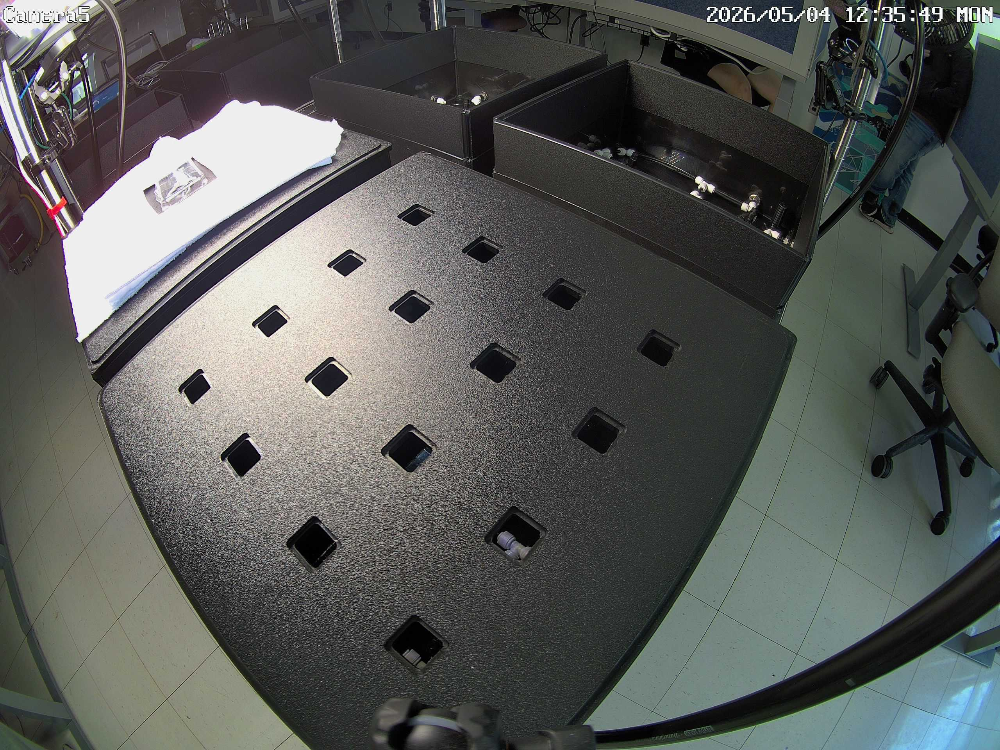

In [5]:
ds["train"][0]["image"]

### view a grid with details

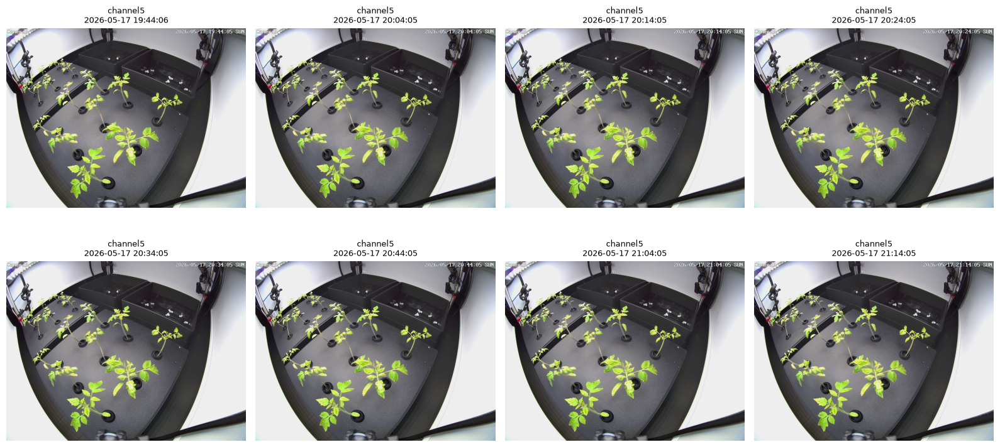

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.flat, ds["train"].select(range(200, 208))):
    ax.imshow(row["image"])
    ax.set_title(f'{row["channel"]}\n{row["date"]} {row["time"]}', fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### table of details without loading images

In [3]:
df = ds["train"].remove_columns("image").to_pandas()
df.head()

,channel,date,time,suitable
0,channel5,2026-05-04,12:35:49,True
1,channel5,2026-05-04,12:45:49,True
2,channel5,2026-05-04,12:55:49,True
3,channel5,2026-05-04,13:05:49,True
4,channel5,2026-05-04,13:15:49,True


### Scoring pictures based on how much colour they have

In [12]:
import numpy as np

GREEN_MARGIN = 15  # green must beat both red and blue by this much (0-255)
MIN_BRIGHTNESS = 40  # ignore very dark pixels (0-255)
GREEN_PIXEL_FRACTION = 0.00001  # image has plants if more than this fraction is green
NUM_PROC = 8


def greenness(img):
    """Fraction of bright pixels where green clearly dominates (0.0 for grayscale/dark)."""
    if img is None or img.mode in ("1", "L", "LA", "I", "I;16", "F"):
        return 0.0
    img = img.convert("RGB")
    img.thumbnail((256, 256))
    px = np.asarray(img, dtype=np.int16)
    r, g, b = px[..., 0], px[..., 1], px[..., 2]
    is_green = ((g - np.maximum(r, b)) > GREEN_MARGIN) & (g > MIN_BRIGHTNESS)
    return float(is_green.mean())


def score_batch(images):
    return {"greenness": [greenness(im) for im in images]}


scored_ds = ds.map(
    score_batch,
    batched=True,
    batch_size=32,
    input_columns=["image"],
    num_proc=NUM_PROC,
    desc="Scoring",
)
green_ds = scored_ds.filter(
    lambda s: s > GREEN_PIXEL_FRACTION, input_columns="greenness", num_proc=NUM_PROC
)
no_green_ds = scored_ds.filter(
    lambda s: s <= GREEN_PIXEL_FRACTION, input_columns="greenness", num_proc=NUM_PROC
)

for split in scored_ds:
    print(
        f"{split}: total {len(scored_ds[split])}, "
        f"green {len(green_ds[split])}, no green {len(no_green_ds[split])}"
    )

Filter (num_proc=8):   0%|          | 0/5248 [00:00<?, ? examples/s]

Filter (num_proc=8):   0%|          | 0/5248 [00:00<?, ? examples/s]

train: total 5248, green 3163, no green 2085


### Check the split

Look at the score distribution and some images from each group. If color images land in the black-and-white group (or vice versa), adjust `COLOR_PIXEL_FRACTION` / `CHROMA_THRESHOLD` above.

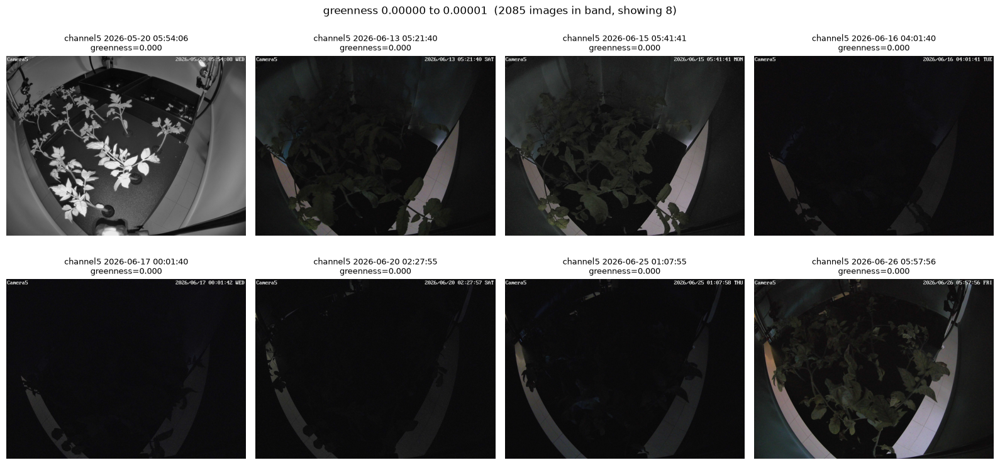

greenness 0.00001 to 0.00002: no images


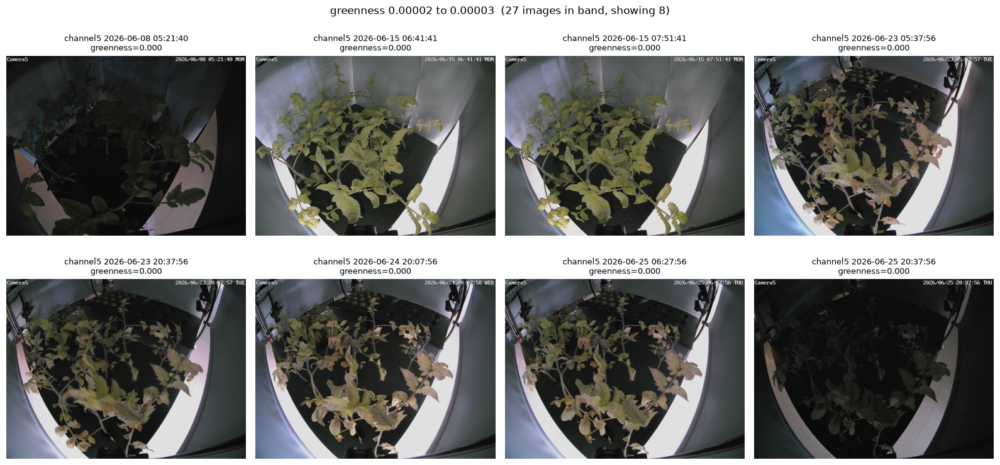

greenness 0.00003 to 0.00004: no images


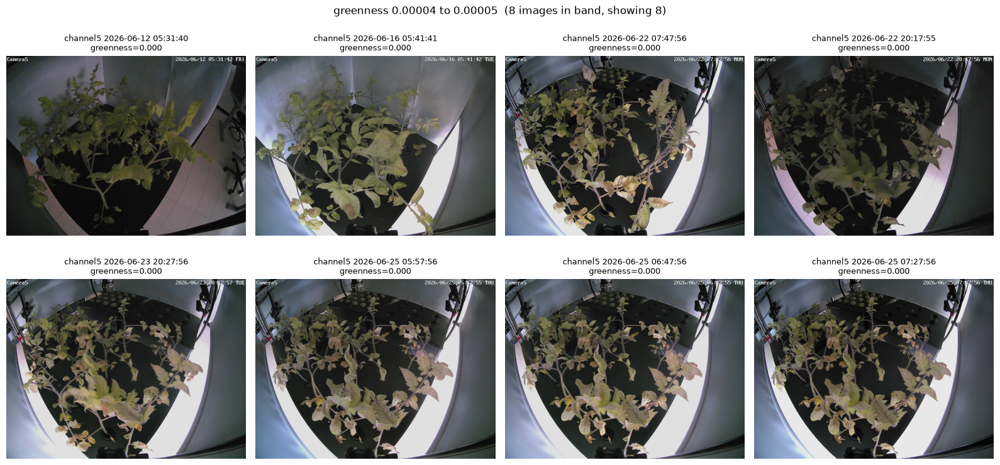

greenness 0.00005 to 0.00006: no images


KeyboardInterrupt: 

In [11]:
import numpy as np
import matplotlib.pyplot as plt


def show_bands(dataset, column="greenness", n=8, width=0.00001, max_score=0.01, seed=None):
    scores = np.asarray(dataset[column])  # column only, no image decoding
    n_bands = int(np.ceil(max_score / width - 1e-9))
    decimals = max(1, int(np.ceil(-np.log10(width) - 1e-9)))
    band = np.minimum(
        np.floor(scores / width + 1e-9).astype(int), n_bands - 1
    )  # last band = everything above
    rng = np.random.default_rng(seed)

    for b in range(n_bands):
        lo, hi = b * width, (b + 1) * width
        last = b == n_bands - 1
        members = np.flatnonzero(band == b)
        label = f"{column} {lo:.{decimals}f} to {'max' if last else f'{hi:.{decimals}f}'}"
        if len(members) == 0:
            print(f"{label}: no images")
            continue

        k = min(n, len(members))
        idx = np.sort(rng.choice(members, size=k, replace=False))

        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        fig.suptitle(f"{label}  ({len(members)} images in band, showing {k})")
        for ax in axes.flat:
            ax.axis("off")
        for ax, row in zip(axes.flat, dataset.select(idx)):
            ax.imshow(row["image"])
            ax.set_title(
                f"{row['channel']} {row['date']} {row['time']}\n{column}={row[column]:.3f}",
                fontsize=9,
            )
        plt.tight_layout()
        plt.show()


show_bands(scored_ds["train"])

In [17]:
from datasets import DatasetDict

ds_flagged = DatasetDict(
    {
        split: ds[split]
        .remove_columns("suitable")
        .add_column(
            "suitable",
            [g > GREEN_PIXEL_FRACTION for g in scored_ds[split]["greenness"]],
        )
        for split in ds
    }
)

for split in ds_flagged:
    n_true = sum(ds_flagged[split]["suitable"])
    print(
        f"{split}: suitable={n_true} (ds_color: {len(ds_color[split])}), "
        f"not suitable={len(ds_flagged[split]) - n_true}"
    )

train: suitable=3163 (ds_color: 3163), not suitable=2085


### Update the dataset

In [ ]:
ds.push_to_hub("regularpooria/canopymap_plants", private=True)